In [1]:

# ============================================================
# Course setup: Run this cell to copy all the necessecary files from the github to your local drive area.
# Only run if using online colab; if using a local copy e.g. through jupyter notebook, this cell is unnecessecary
# ============================================================

import os
import sys
import shutil

REPO_URL = "https://github.com/IanEstabrook/Theory_Cell_Motion_On_Substrates_EMBLPredocCourse2026.git"
REPO_DIR = "/content/Theory_Cell_Motion_On_Substrates_EMBLPredocCourse2026"

# Move outside the repository before deleting it
os.chdir("/content")

# Force-remove the existing repository
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)

# Clone the latest version
!git clone -q {REPO_URL} {REPO_DIR}

# Make the course package available to Python
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

os.chdir(REPO_DIR)
print(f"Course repository updated: {REPO_DIR}")

fatal: could not create leading directories of '/content/Theory_Cell_Motion_On_Substrates_EMBLPredocCourse2026': Permission denied


FileNotFoundError: [Errno 2] No such file or directory: '/content/Theory_Cell_Motion_On_Substrates_EMBLPredocCourse2026'

In [2]:
from IPython.display import display, HTML

display(HTML("""<style>.jp-RenderedHTMLCommon,.jp-RenderedHTMLCommon p,.jp-RenderedHTMLCommon li {    font-size: 40px !important;}
.rendered_html,.rendered_html p,.rendered_html li {    font-size: 20px !important;}</style>"""))

## Adhesion driven motility through biological friction: modelling

## A one dimensional Microscopic model of cell motion through adherence to a surface:

In this exercise, we are going to describe one method of locomotion which cells can use to move on a substrate.  By adhering to a surface, cells are able to generate forces between the substrate and the cell surface, which can then result in motion generated through biological friction. To begin with, we will use a 1D model, analytically and computationally, to understand how biological friction occurs, and what it can tell us about the motion of a cell. 

The adherence model we describe here is based on the Lacker-Peskin model, which was originally developed to describe the ways muscles generate force, but the mathematical descriptions of which are largely shared. The emergence of biological friction can be observed in a system made of transient elastic linkers (e.g. cadherins) that bind and unbind two opposing interfaces (e.g. cell surfaces and the substrate a cell attempts to move on.).

Our model consists of elastic linkers connected to these surfaces, which then results in a relative velocity $v$  between the interfaces, which stretches the linkers (initially proportional to $v t$, with $t$ time). 

The dynamics of the Linkers is as follows: in each short period of time (a timestep), Linkers can either bind, at a rate $k_{\rm on}$, or unbind to the substrate. 

In the model, in each timestep, a random number of linkers will unbind proportional to a rate $k_{\rm off}$. In real biological systems, this is typically related to the force applied to the linker. For a linear elastic relation, Hooke's Law, this is proportional to the degree of stretching of the linker, and has form 

$F=- k\epsilon$

with $\epsilon$ the stretch (strain) of the linker and $k$ the "elastic constant" of the spring. This is the force felt by the linker. The traction force actually transferred to the cell is different, as part of the force will be expended to deform the substrate. 

For the moment, we prescribe that each linker is capable of exerting a specific active force, $F_{act}$, that is transferred from the substrate, which will propel the cell in the direction of this force. For the moment, we do not account for the deformations of the substrate for the moment.

Small warning: Unfortunately, I did not decide the letters defined in literature, k as a spring constant and k with subscripts which is about binding and unbinding rates of, in our case, adhering molecules, as follows are both standard notation, but represent very different things. 

We will explore 3 different scenarios for how linkers can behave:

1.    Ideal bonds, for which the rate of unbinding, $k_{\rm off}$ is independent of the force.
2.    Slip bonds, whose unbinding rate increases with force, e.g. $k_{\rm off} = k_{\rm off}^0 e^{\epsilon/\epsilon_0}$.
3.    Catch bonds, whose unbinding rate decreases with force, e.g. $k_{\rm off} = k_{\rm off}^0 e^{-\epsilon/\epsilon_0}$.

Bonds attach again at a rate given by $k_{\rm on}$, and they always attach at in an unstretched state (zero strain) ($\epsilon=0$). See the sketch below.

Some interesting questions that this model can address are: How does the population of linkers evolve? What is the force that one needs to apply to displace the interfaces?



![ExampleOfCellMotionFigure](Figures/cell_diagram_newly_adhered.png)

The following python code provides a framework to simulate this system. Such a statistical system can be explored numerically, as long as your timestep (dt) is much smaller than the events - here, meaning binding and unbinding events, as well as stretching of linkers through the cell velocity - you're trying to probe.

The computational approach we will build for a one dimensional- motion of a cell is as follows: 
We will model a finite set of n_bonds linkers, which can either be bound and under a prescribed level of stretch, or unbound and not stretched at all. A linker between the cell surface and underlying substrate then progressively more stretched as the   The model is stochastic: the rates described above correspond to probabilities of something happening in a small timestep, and also need to be treated probalistically in simulations. 

In each timestep $\Delta t$, for each linker independently, we have two probabilities: the probability that it binds (if currently unbound) is given by $k_\text{on} \Delta t$, and the probability that it unbinds (if currently bound) is given by $k_\text{off} \Delta t$.

When bound, a linker's length $\epsilon$ increases by $v\Delta t$ each timestep.

In [3]:
import numpy as np
from matplotlib import pyplot as plt

# Input parameters
n_bonds = 100 #The maximum number of bonds along the cell surface. 
#In practice, this will be a function of the area of the cell surface and actomyosin dynamics

k_on = 1.E-1 #The rate at which a given linker binds when unbound
k_off = 1.E-1 #The rate at which a given bound linker unbinds.

# Mechanical parameters
k = 0.01           # Linker spring stiffness
F_actLinker = 1.0        # Active force on the cell from each linker, transferred from the substrate.
zeta = 10.0        # Effective drag coefficient

#Initial cell position : x 
x=0;
# Time integration
t_max = 100.0
dt = 0.001 #dt=timestep: \Delta t in exercise 3.
time = np.linspace(0,t_max,int(t_max/dt))
dt = time[1]-time[0]

# Variables
stretch = np.zeros(n_bonds)
state = np.zeros(n_bonds,dtype=bool)

# Loop in time
for t in time:

    state_n = np.copy(state)
    
    #Calculate the force exerted by each of the bound linkers on the cell in their unstretched state:
    F_act=F_actLinker* np.sum(state_n)

    # [1] Calculate the total force on the linkers caused by the stretching of linkers
    F_link = -k * np.sum(stretch[state_n])

    # [2] Calculate cell velocity from force balance
    v = (F_act + F_link) / zeta

    # [3] Update cell position
    x += v * dt
    
    # [4] Stretch bound linkers
    stretch[state_n] += v * dt

    # [5] Unbind
    unbind = np.random.rand(np.sum(state_n)) < k_off * dt
    state[state_n] = np.logical_not(unbind)

    # Reset extensions of unbound linkers
    stretch[~state] = 0.0

    # [6] Bind
    bind = np.random.rand(n_bonds-np.sum(state_n)) < k_on * dt
    state[~state_n] = bind

    # [7] Record quantities- what should you record?


### Exercise 1.1:

(Can be solved with equations or computationally!) For ideal bonds: What is the proportion of bound VS unbound linkers for $F_{act}=0$? Do you expect that proportion to change for $F_{act}\neq 0$? Why? In the code, does initial choice of  linkers bound affect the long time behaviour?

### Exercise 1.2
Assuming $k=1$, simulate to determine the average force over time, $F(t)$ exerted by the linkers as a function of time. What is the behaviour of $F(t)$ for $t k_{\rm off} \ll 1$ and for $t k_{\rm off} \gg 1$? How does this relate to solid like or fluid like behaviour?

### Exercise 1.3
   Plot the probability (histogram) of $\epsilon$, $p_{\rm on}(\epsilon)$, at different times of the time-evolution. What is the initial behaviour of the histogram ($t k_{\rm off} \ll 1$)? Does the histogram reach a steady state ($t k_{\rm off} \gg 1$)?

### Exercise 1.4
   What happens if, instead of ideal bonds one has slip bonds? and for catch bonds?

### Exercise 1.5
Look at the histogram. What happens if you add more bins? What happens if you add more bonds? As the size of bins gets smaller and smaller, with enough bonds, the result should "Approach the continuum limit", which we can later compare with a continuum field theory.


## Field theory

### Exercise 2 & 3 : Deriving a continuum field theory for this system

### Exercise 2: Writing a master equation from how the distribution evolves
Write an expression that describes the number of bound linkers, $p_{on}$ of the system at the next time step $t+\Delta t$. Consider the possible changes to the state $p_{on}(\epsilon,t)$ that change the distribution of linkers. The following figure may be useful in understanding how the distribution of bound linkers can change:

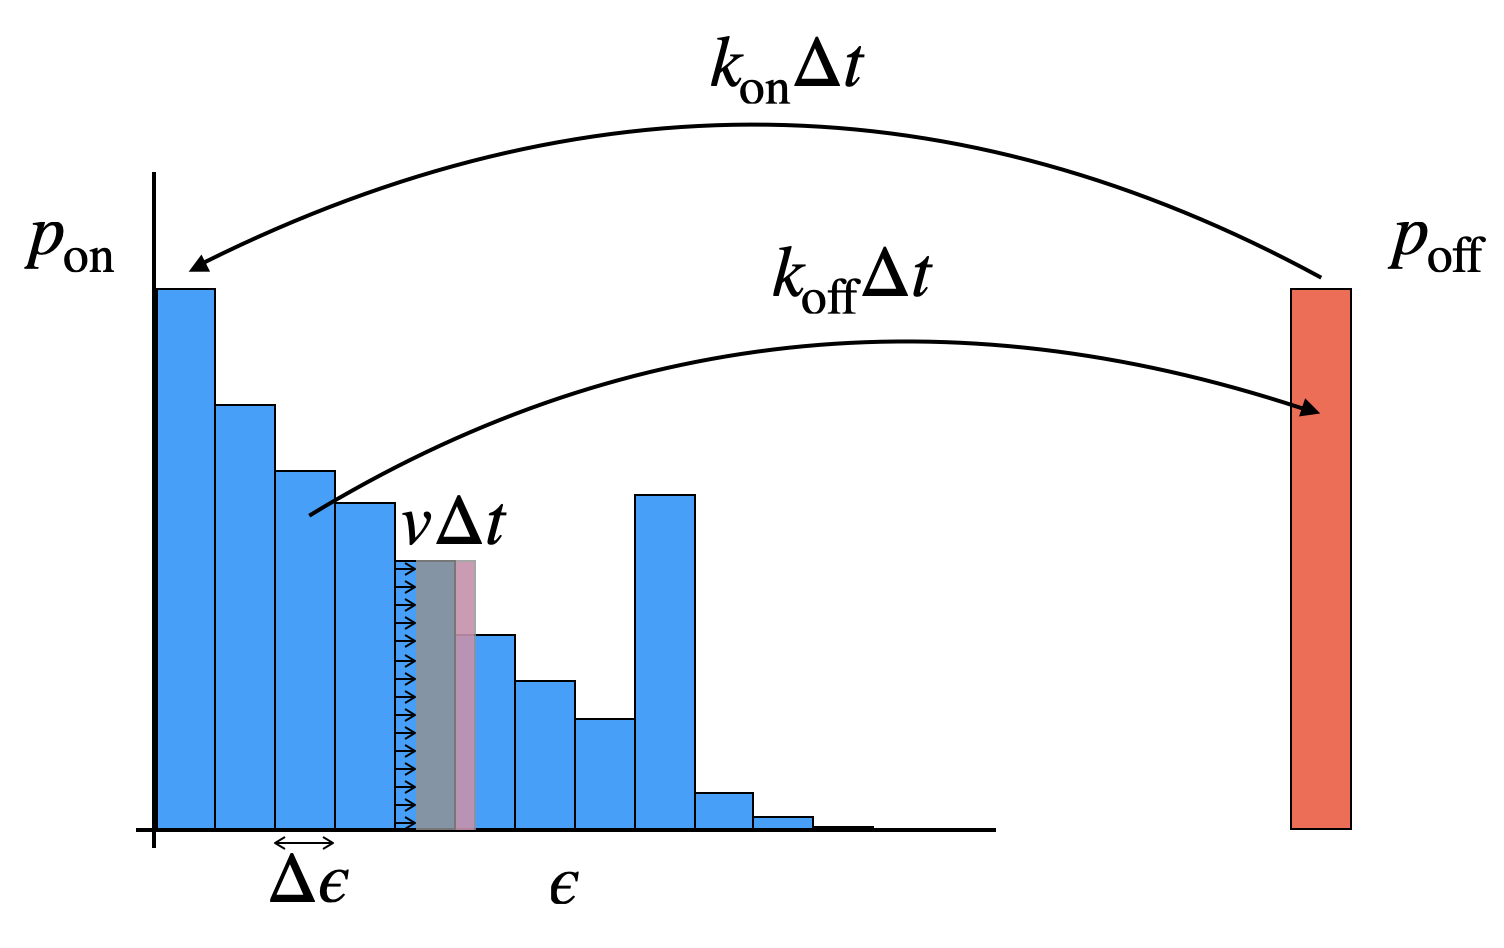

### Exercise 3:

Rates of change of properties and distributions can be described by derivatives. It is possible to approximate derivatives numerically by comparing the change of values of a distribution over a small enough timestep. This relation can be implemented in code by using the following relation:

$$
\frac{\partial f(x,t)}{\partial t} \approx \frac{f(x,t+\Delta t) - f(x,t)}{\Delta t}\quad \text{for small enough timestep } \Delta t\rightarrow 0
$$
to write the result of exercise 2 as a partial differential equation in the limit of $\Delta \epsilon,\Delta t\rightarrow 0$.

The following code implements the solution of the partial differential equation using the approximation given by the solution to exercise 2:

Text(0, 0.5, '$F(t)$')

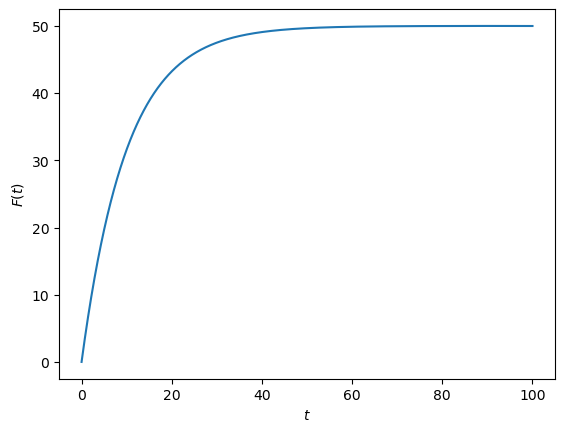

In [4]:
import numpy as np
from matplotlib import pyplot as plt

# Input parameters
v = 10.0
k_off = 1.E-1
k_on = 1.E-1

# Time integration
dt = 0.001
t_max = 100.0
time = np.linspace(0,t_max,int(t_max/dt))
dt = time[1]-time[0]

# Space integration
de = 0.1 #\Delta \epsilon
e_max = 1000.0 #limit on the max stretch. Presumption is that no strains are longer than this.
e = np.linspace(0,e_max,int(e_max/de)) #discretisation of possible strains= histogram bins.  
#print(e)
de = e[1]-e[0]
p_on = np.zeros(e.size)
p_on[0] = k_on/(k_on+k_off)#Start with the distribution of linkers at the steady state 

force = []
for t in time:
    p_off = 1.0-np.sum(p_on)
    p_on[1:] += dt * (v/de * (p_on[:-1] - p_on[1:]) - k_off * p_on[1:])#Update the existing bound linkers
    p_on[0] += dt * (k_on * p_off - v /de * p_on[0] - k_off * p_on[0])#Update the number of linkers bound at 0 stretch (from the unbound state)

    force.append(np.sum(p_on*e))

force = np.array(force)
plt.plot(time, force)
plt.xlabel(r"$t$")
plt.ylabel(r"$F(t)$")


### Exercise 4

1.   Compare the microscopic and continuum models. Do they match?

2.   Implement slip and catch bond behaviour in the continuum model.

3.   For the steady state (that is, waiting long enough to reach a plateau in the force), plot the force as a function of the velocity for ideal and slip bond. Describe the results.


## Exercise 5: Incorporating substrate stiffness properties: Effects on cell motion by having different surface stiffnesses (ignoring shape dynamics still!)

In the previous exercises, the implicit assumption was that the substrate is much stiffer than the linker spring, so that as the cell moves, all shape changes/forces are transmitted to motion of the cell. 

The stiffness of multiple "springs" of different stiffness connected in series can be written 
$$\frac{1}{K_{eff}}=\frac{1}{K_{linker}}+ \frac{1}{K_{substrate}} + ...$$

For just linkers and subtrate interactions
$$K_{eff}=\frac{K_{linker} K_{substrate}}{K_{linker}+K_{substrate}}$$

The second change you might want to make to incorporate how much of the active force actually is transmitter to the cell. Some portion of the force will be expended on deformation of the substrate; the simplest way to incorporate this is a function like:

$$F_{transmitted}=  F_{act} \alpha(K_s, K_l) $$, where $\alpha(K_s,K_l)$ is a transmission function that incorporates the amount of active force that actually results in cell motion, rather than substrate deformation.  A simplistic form of this transmission coefficient would be:

$$\alpha(K_s,K_l) = \frac{K'}{K'+K_0}$$, where $$K'= \frac{K_s}{K_l}$$ is a ratio of substrate stiffness to linker stiffness. 

What behaviours do you expect in the cases where $K_s >> K_l$ ,$K_s \approx K_l$ and $K_s <<K_l$

Incorporate these changes into the code as you modified it from earlier exercises 1, (original version copied below), and see if your intuitiion matches what is simulated

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

# Input parameters
n_bonds = 100 #The maximum number of bonds along the cell surface. 
#In practice, this will be a function of the area of the cell surface and actomyosin dynamics

k_on = 1.E-1 #The rate at which a given linker binds when unbound
k_off = 1.E-1 #The rate at which a given bound linker unbinds.

# Mechanical parameters
K = 0.01           # Linker spring stiffness
F_actLinker = 1.0        # Maximum active force on the cell from each linker
zeta = 10.0        # Effective drag coefficient



# Time integration
t_max = 100.0
dt = 0.001 #dt=timestep: \Delta t in exercise 3.
time = np.linspace(0,t_max,int(t_max/dt))
dt = time[1]-time[0]

# Variables
stretch = np.zeros(n_bonds)
state = np.zeros(n_bonds,dtype=bool)

# Loop in time
for t in time:

    state_n = np.copy(state)
    
    #Calculate the force exerted by each of the bound linkers on the cell in their unstretched state:
    F_act=F_actLinker* np.sum(state_n)

    # [1] Calculate the total force on the linkers caused by the stretching of linkers
    F_link = -K * np.sum(stretch[state_n])

    # [2] Calculate cell velocity from force balance
    v = (F_act + F_link) / zeta

    # [3] Update cell position
    x += v * dt

    # [4] Stretch bound linkers
    stretch[state_n] += v * dt

    # [5] Unbind
    unbind = np.random.rand(np.sum(state_n)) < k_off * dt
    state[state_n] = np.logical_not(unbind)

    # Reset extensions of unbound linkers
    stretch[~state] = 0.0

    # [6] Bind
    bind = np.random.rand(n_bonds-np.sum(state_n)) < k_on * dt
    state[~state_n] = bind

    # [7] Record quantities- what should you record?

## Exercise 6: two-dimensional cell motion with transient linkers

Up to now, we have described only a cell moving in a single, prescribed direction. However, cells on a substrate are, of course, moving on a two dimensional surface. The last exercises here are now build towards incorporating the 2d surface and understanding a cells motion on a substrate. 

The key parameters that we need to change in the 1D model to generalise it to 2D are that the extension $\epsilon$, which was previously only a single value per linker, and the cell velocity $v$ where we only measured the speed, rather than speed and direction, need to be replaced with vectors, i.e. tracking both magnitude and direction components. Such an extension can keep the linker kinetics of the Lacker–Peskin model, but allows the cell to move in an arbitrary direction relative to the underlying substrate plane.

### Summary of modelling choices and assumptions (rewrite as exercises develop)?

How do we move from a 1D to a 2D model? We need to change the following parameters to have a 2D, vector based, form.

- The position of the cell, which is now a point in 2D space that changes with time :$\mathbf{x}(t)=(x(t),y(t)).$ 

- Each linker can still be bound or unbound, and when binding, does so at 0 extension. The extension then has to be measured in a two dimensional way :  ${\bf{\epsilon}}_i=(\epsilon_{ix},\epsilon_{iy})$. 

- While bound, the extension is incremented by the motion of the cell $\dot{\bf{\epsilon}}_i={\bf{v}}$

- We still use the isotropic Hookean linker force from the previous exercises. Force is also a vector now, and so must have a prescribed direction: The active force $F_{act}$ has to also be 2D. The resulting force exerted on linker i by stretching an amount $\epsilon$ is $F_{link}= -k{\bf{\epsilon}}_i$.

- Linkers bind at rate $k_{\rm on}$. For the first implementation, use ideal unbinding at rate $k_{\rm off}$. The unbinding rate can be force independent, or dependent as with the previous catch/slip bonds. Start with force independence again, before allowing them to change with linker tension/strain.

- The position and velocity of the cell are updated mechanically through an overdamped force balance:

  $  \zeta{\bf{v}}={\bf{F}}_{\rm act} +{\bf{F}}_{\rm link} ={\bf{F}}_{\rm act} -k\sum_{i\in\mathrm{bound}}{\bf{\epsilon}}_i.$
  
  $\zeta$ is an effective drag coefficient which opposes motion of the cell, for instance due to resistance caused by trying to move the cell against the fluid it lives within.

As mentioned before, this still does not deliberately incorporate shape, as well as other interactions such as local adhesion positions, actin dynamics, or spatial variations in substrate properties. However, we will build to that (shape is complicated!)


### Exercise 6.1 — Implement a 2D stochastic simulation of a point particle

The code below contains an example of how a 2D point particle might move under noisy force. Generally, you can try changing parameters below and compare it to your 1D simulations. Example questions you might want to test that couldn't be done in 1D include: 

Does the cell move parallel to the active force at long times? 
How does changing the unbinding rate affect teh speed and persistence of the cells motion. Do catch and slip bonds affect the directions the cells take? Try changing $k_{\rm off}$ and seeing if it alters these properties

What happens to the cell velocities and linker populations when the active force magnitude is changed?

You can also try different random seeds
Compare trajectories from different random seeds. What features of the cell motion are consistent between simulations, and which are stochastic?


## Shape dynamics simulations are handled separately in a different notebook as they're significantly more complex, see Modelling_2d_cell_shapes.ipynb

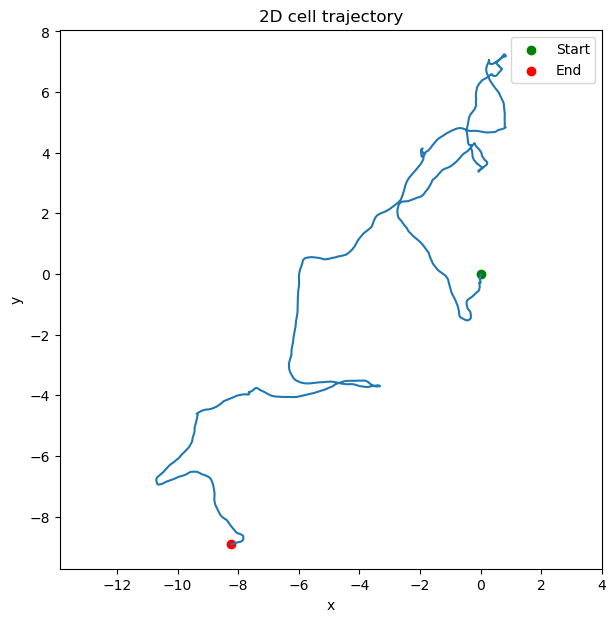

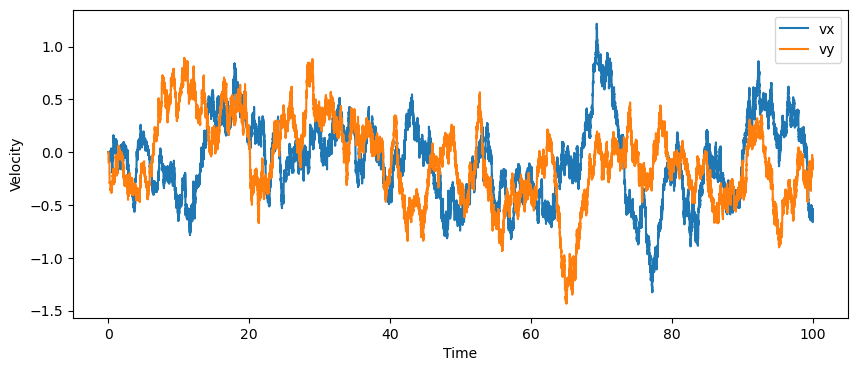

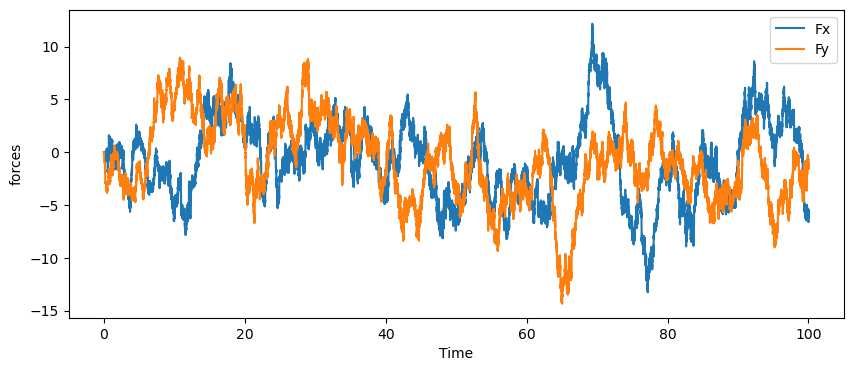

In [6]:
import numpy as np
from matplotlib import pyplot as plt

# Input parameters
n_bonds = 100
k_on = 1.E-1
k_off = 1.E-1

# Mechanical parameters
K = 0.01
F_actLinker = 1.0
zeta = 10.0

D_r = 0.1  # Rotational diffusion coefficient

# Time integration
t_max = 100.0
dt = 0.001

time = np.arange(0, t_max, dt)
n_steps = len(time)

# Variables
x = np.zeros((n_steps, 2))

stretch = np.zeros((n_bonds, 2))
state = np.zeros(n_bonds, dtype=bool)

# Assign a preferred direction to each linker. For now, we assign only one direction, later you may want
#to change this, e.g. by location, by giving every bond a different thete.
#theta = np.ones(n_bonds)*np.pi/9.0
theta = np.random.uniform(0, 2*np.pi, n_bonds)

direction = np.column_stack((np.cos(theta), np.sin(theta)))

# Store velocity
velocity = np.zeros((n_steps, 2))
forces = np.zeros((n_steps, 2))

# Loop in time
for j, t in enumerate(time[:-1]):

    state_n = np.copy(state)

    # [1] Active force from bound linkers
    F_act = F_actLinker * np.sum(direction[state_n], axis=0)

    # [2] Elastic force from stretched linkers, acts against the direction of linker stretch
    F_link = -K * np.sum(stretch[state_n], axis=0)

    # [3] Calculate cell velocity from the forces and overdamped dynamics
    v = (F_act + F_link) / zeta

    velocity[j] = v
    forces[j] =F_act+F_link
    # [4] Update cell position
    x[j+1] = x[j] + v * dt

    # [5] Update extensions of bound linkers
    stretch[state_n] += v * dt

    # [6] Unbind
    unbind = np.random.rand(np.sum(state_n)) < k_off * dt
    state[state_n] = np.logical_not(unbind)

    # Reset extensions of unbound linkers
    stretch[~state] = 0.0

    # [7] Bind
    bind = np.random.rand(n_bonds - np.sum(state_n)) < k_on * dt
    state[~state_n] = bind

    # Rotational noise
    theta += np.sqrt(2 * D_r * dt) * np.random.randn(n_bonds)

    # Update linker directions
    direction = np.column_stack((np.cos(theta),np.sin(theta)))
    
velocity[-1] = velocity[-2]
forces[-1]= forces[-2]
# Plot cell trajectory
plt.figure(figsize=(7, 7))
plt.plot(x[:, 0], x[:, 1])
plt.scatter(x[0, 0], x[0, 1], color='green',label='Start')
plt.scatter(x[-1, 0], x[-1, 1], color='red',label='End')

plt.xlabel('x')
plt.ylabel('y')
plt.title('2D cell trajectory')
plt.axis('equal')
plt.legend()
plt.show()

# Plot velocity components
plt.figure(figsize=(10, 4))
plt.plot(time, velocity[:, 0], label='vx')
plt.plot(time, velocity[:, 1], label='vy')
plt.xlabel('Time')
plt.ylabel('Velocity')
plt.legend()
plt.show()


# Plot velocity components
plt.figure(figsize=(10, 4))
plt.plot(time, forces[:, 0], label='Fx')
plt.plot(time, forces[:, 1], label='Fy')
plt.xlabel('Time')
plt.ylabel('forces')
plt.legend()
plt.show()



## Other elastic models: Maxwell model.

In previous years, the theory course has explored other models of elastic - fluid behaviour, that are typical in biology. We won't have time for this year really, but for anyone who is interested, I've left some information frrom the previous year below.

A classical way to represent a fluid viscoelastic response, such as the one emerging from the Lacker-Peskin model, is through a Maxwell model, a 1D model that represents a spring immersed in a very viscous fluid:

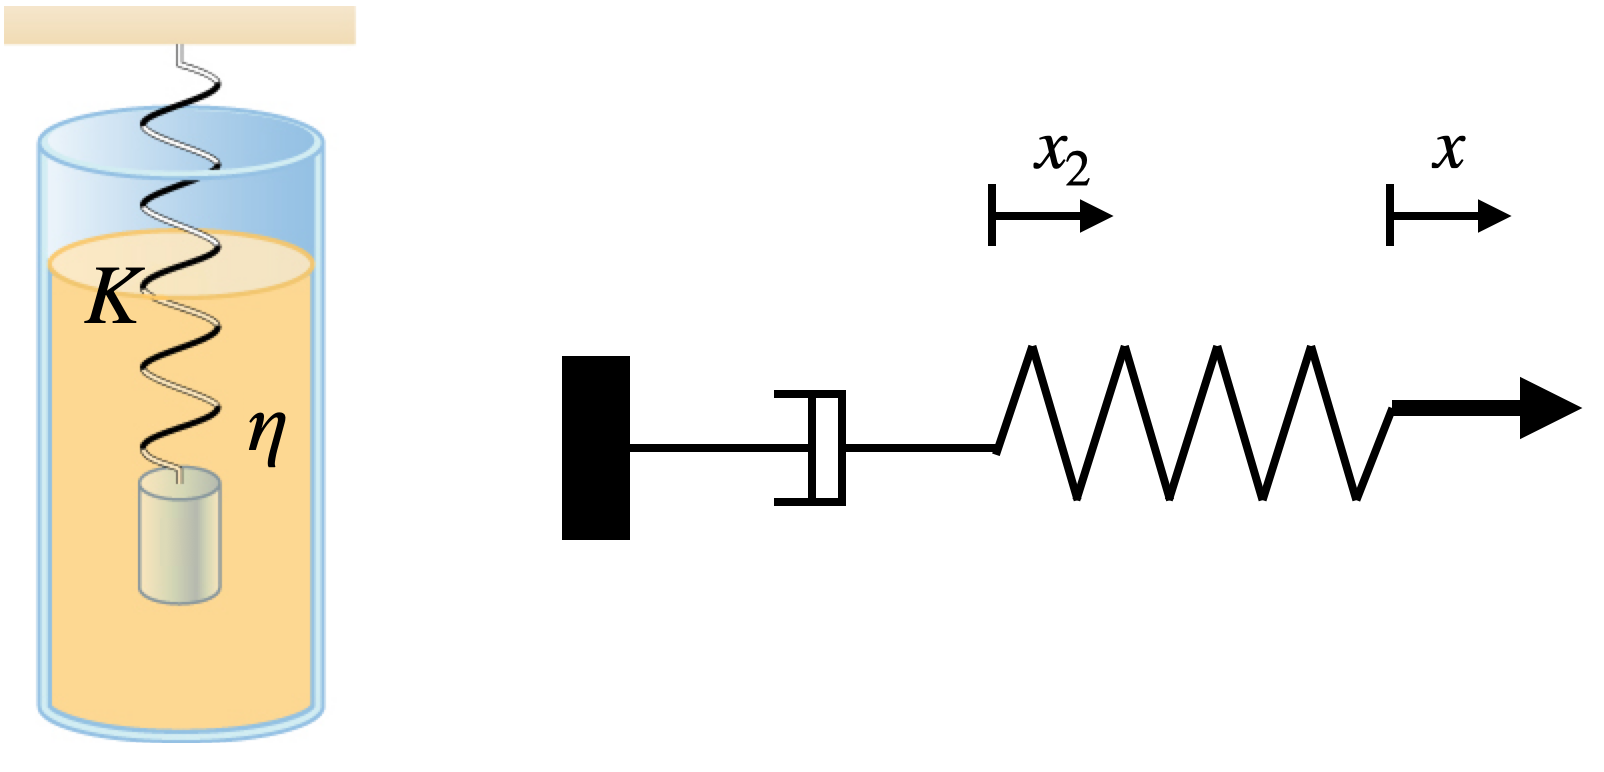



Assuming that the mass of the spring is very small, for a spring of stiffness k, in a fluid of viscosity $\eta $, the force balance of forces is given by the stretching of the string against the viscous friction (drag)

$$
F = k(x-x_2) = \eta \frac{dx_2}{dt}
$$
where $F$ is some external force (e.g. gravity). This expression can be manipulated further by taking time derivatives
$$
\frac{dF}{dt} = k\left(\frac{dx}{dt}-\frac{dx_2}{dt}\right) = k \frac{dx}{dt} - \frac{k}{\eta} F \rightarrow \frac{dF}{dt} + \frac{k}{\eta} F = k\frac{dx}{dt}.
$$
For a constant pulling velocity $v=dx/dt$, this leads to
$$
F(t) = \eta v (1 - e^{-tk/\eta})
$$

### Exercise one million:
Plot the solution to the Maxwell model assuming $K$ and $\eta$ from the Lacker-Peskin model for ideal bonds ($K$ being the initial slope of $F(t)$ and $\eta$ being the ratio $F/v$ in the steady state). What do you see? Can you explain why? *Hint: in the continuum model, compute $F(t)=\int_0^\infty p_{\rm on}(\epsilon,t) \epsilon d\epsilon$ and try to compute $\dot{F}(t)$ by using the expression for $\partial_t p_{\rm on}$*

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

v = 1.0
k_off = 1.E-1
k_on = 1.E-1
dt = 0.001
t_max = 100.0
time = np.linspace(0,t_max,int(t_max/dt))

K = k_on/(k_on+k_off)
eta = k_on/k_off/(k_on+k_off)
force = (1 - np.exp(-time*K/eta)) * eta * v

plt.plot(time,force)
plt.show()

### Analytical explanation for interest:

In the Lacker-Peskin model, we can use the expression of the force and calculcate its time derivative. 

The force for each linker is proportional to the strain it is under : $f_{\rm on} = k \epsilon$. The total force is the integral of the expected distribution of bound linkers, $p(\epsilon,t)_{on}$ over the range of possible strains:

One can manipulate the expression inserting the evolution law for $p_{\rm on}$:
$$
F(t) = k\int_0^\infty p_{\rm on}(\epsilon,t) \epsilon d\epsilon $$

$$\rightarrow \dot{F} = k\int_0^\infty \partial_t p_{\rm on}(\epsilon,t) \epsilon d\epsilon $$
$$= k\int_0^\infty \left[-v\partial_\epsilon p_{\rm on}(\epsilon,t) + k_{\rm on} \delta(\epsilon) p_{\rm off}(t) -k_{\rm off}(\epsilon) p_{\rm on} (\epsilon,t)\right] \epsilon d\epsilon$$
$$=  -k\int_0^\infty v\left\{\partial_\epsilon \left[p_{\rm on}(\epsilon,t) \epsilon\right] - p_{\rm on}(\epsilon,t)\right\} d\epsilon -k\int_0^\infty k_{\rm off}(\epsilon) p_{\rm on} (\epsilon,t)\epsilon d\epsilon $$

For the case of ideal or slip  bonds, where $\epsilon p(\epsilon,t)_{on} \rightarrow 0 $ as $\epsilon ->\infty$
$$= k v \int_0^\infty p_{\rm on}(\epsilon,t) d\epsilon -k\int_0^\infty k_{\rm off}(\epsilon) p_{\rm on} (\epsilon,t)\epsilon d\epsilon.
$$
This expression, in general, cannot be simplified further. However, for the case of ideal bonds, the first integral is a constant, $p_{\rm on}$, and from the second integral, $k_{\rm off}$ is a constant and so can be removed from the integral to get expression in terms of the force:

For ideal bonds:
$$
\dot{F} =  k v p_{\rm on} -k_{\rm off} F,
$$
or
$$
\frac{\dot{F}}{k p_{\rm on}} + \frac{k_{\rm off} F}{k p_{\rm on}} = v.
$$

The Lacker-Peskin model is therefore equivalent to a Maxwell model with elastic constant
$$
K = k p_{\rm on} = k \frac{k_{\rm on}}{k_{\rm on}+k_{\rm off}},
$$
and viscous coefficient
$$
\eta = \frac{k}{k_{\rm off}} p_{\rm on} = k \frac{k_{\rm on}/k_{\rm off}}{k_{\rm on}+k_{\rm off}}.
$$

In the Lacker-Peskin model, we can use the expression of the force and calculcate its time derivative. One can manipulate the expression inserting the evolution law for $f_{\rm on}$:
$$
F(t) = k\int_0^\infty f_{\rm on}(\epsilon,t) \epsilon d\epsilon \rightarrow \dot{F} = k\int_0^\infty \partial_t f_{\rm on}(\epsilon,t) \epsilon d\epsilon = k\int_0^\infty \left[-v\partial_\epsilon f_{\rm on}(\epsilon,t) + k_{\rm on} \delta(\epsilon) f_{\rm off}(t) -k_{\rm off}(\epsilon) f_{\rm on} (\epsilon,t)\right] \epsilon d\epsilon
=  -k\int_0^\infty v\left\{\partial_\epsilon \left[f_{\rm on}(\epsilon,t) \epsilon\right] - f_{\rm on}(\epsilon,t)\right\} d\epsilon -k\int_0^\infty k_{\rm off}(\epsilon) f_{\rm on} (\epsilon,t) d\epsilon = k v \int_0^\infty f_{\rm on}(\epsilon,t) d\epsilon -k\int_0^\infty k_{\rm off}(\epsilon) f_{\rm on} (\epsilon,t) d\epsilon.
$$
This expression, in general, cannot be simplified further. However, for the case of ideal bonds, the first integral is a constant, $p_{\rm on}$, and from the second integral one can extract $k_{\rm off}$ to get the force:

For ideal bonds:
$$
\dot{F} =  k v p_{\rm on} -k_{\rm off} F,
$$
or
$$
\frac{\dot{F}}{k p_{\rm on}} + \frac{k_{\rm off} F}{k p_{\rm on}} = v.
$$
The Lacker-Peskin model is therefore equivalent to a Maxwell model with elastic constant
$$
K = k p_{\rm on} = k \frac{k_{\rm on}}{k_{\rm on}+k_{\rm off}},
$$
and viscous coefficient
$$
\eta = \frac{k}{k_{\rm off}} p_{\rm on} = k \frac{k_{\rm on}/k_{\rm off}}{k_{\rm on}+k_{\rm off}}.
$$